 **Import Library**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan, het_white, lilliefors
from statsmodels.stats.stattools import jarque_bera

sns.set_style("whitegrid")
pd.options.display.float_format = "{:.4f}".format
ALPHA = 0.05   # taraf signifikansi

In [ ]:
from google.colab import files
uploaded = files.upload()
PATH = list(uploaded.keys())[0]
print("File dipakai:", PATH)

Saving Dataset - sandi fadia.xlsx to Dataset - sandi fadia.xlsx
File dipakai: Dataset - sandi fadia.xlsx


In [ ]:
raw = pd.read_excel(PATH)
raw = raw.iloc[:, :4]
raw.columns = ["Provinsi", "X1_IPM", "X2_Gini", "Y_Miskin"]

# Baris kosong & baris catatan sumber (URL) dibuang
df = raw.copy()
for c in ["X1_IPM", "X2_Gini", "Y_Miskin"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df = df.dropna(how="all", subset=["X1_IPM", "X2_Gini", "Y_Miskin"]).reset_index(drop=True)

print("Jumlah observasi (provinsi):", len(df))
df.head()

Jumlah observasi (provinsi): 38


,Provinsi,X1_IPM,X2_Gini,Y_Miskin
0,Aceh,75.3600,0.2940,14.2300
1,Sumatera Utara,75.7600,0.2970,7.9900
2,Sumatera Barat,76.4300,0.2830,5.9700
3,Riau,75.6700,0.3070,6.6700
4,Jambi,74.3600,0.3210,7.1000


**Cek data kosong dan duplikat**

In [ ]:
cek = pd.DataFrame({
    "Jumlah kosong": df.isna().sum(),
    "Persen kosong (%)": df.isna().mean() * 100
})
display(cek)
print("Duplikat baris   :", df.duplicated().sum())
print("Duplikat provinsi:", df["Provinsi"].duplicated().sum())

if df.isna().sum().sum() == 0:
    print("\n Tidak ada data kosong.")
else:
    print("\n Ada data kosong - tentukan penanganan (hapus baris / imputasi).")

,Jumlah kosong,Persen kosong (%)
Provinsi,0,0.0000
X1_IPM,0,0.0000
X2_Gini,0,0.0000
Y_Miskin,0,0.0000


Duplikat baris   : 0
Duplikat provinsi: 0

 Tidak ada data kosong.


**Cek tipe data**

In [ ]:
display(df.dtypes.to_frame("Tipe data"))
assert all(pd.api.types.is_numeric_dtype(df[c]) for c in ["X1_IPM", "X2_Gini", "Y_Miskin"]), "Ada variabel yang belum numerik."
print("Seluruh variabel X dan Y bertipe numerik.")

,Tipe data
Provinsi,object
X1_IPM,float64
X2_Gini,float64
Y_Miskin,float64


Seluruh variabel X dan Y bertipe numerik.


**Outlier (IQR, Z-score, boxplot)**

,Batas bawah (IQR),Batas atas (IQR),Outlier IQR,Outlier |Z|>3
Variabel,,,,
X1_IPM,66.7800,80.8800,"DKI Jakarta, DI Yogyakarta, Papua Tengah, Papua Pegunungan",Papua Pegunungan
X2_Gini,0.2091,0.4601,-,-
Y_Miskin,-5.2937,25.6762,"Papua Tengah, Papua Pegunungan",Papua Pegunungan


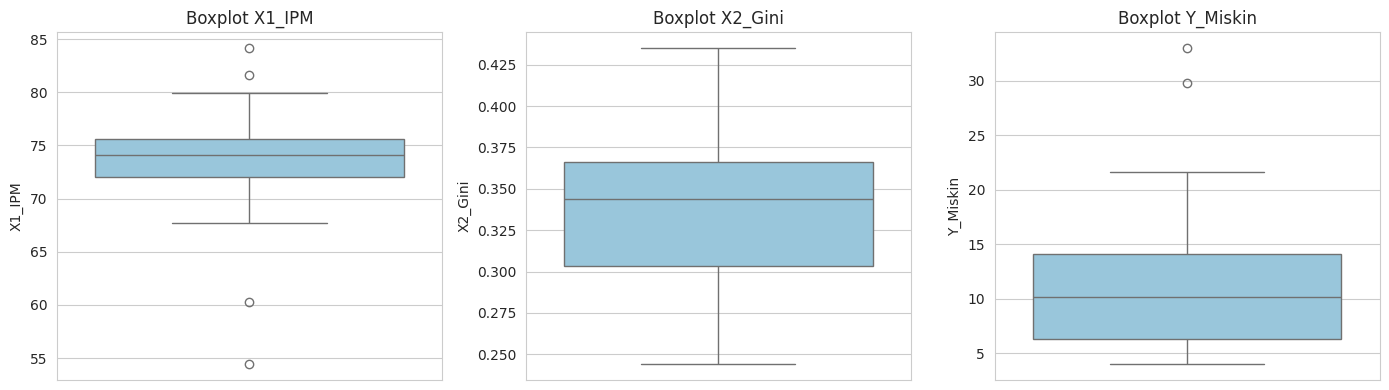

In [ ]:
vars_ = ["X1_IPM", "X2_Gini", "Y_Miskin"]

hasil = []
for v in vars_:
    q1, q3 = df[v].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (df[v] - df[v].mean()) / df[v].std()
    out_iqr = df.loc[(df[v] < lo) | (df[v] > hi), "Provinsi"].tolist()
    out_z = df.loc[z.abs() > 3, "Provinsi"].tolist()
    hasil.append({"Variabel": v, "Batas bawah (IQR)": lo, "Batas atas (IQR)": hi,
                  "Outlier IQR": ", ".join(out_iqr) or "-",
                  "Outlier |Z|>3": ", ".join(out_z) or "-"})
pd.set_option("display.max_colwidth", None)
display(pd.DataFrame(hasil).set_index("Variabel"))

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, v in zip(ax, vars_):
    sns.boxplot(y=df[v], ax=a, color="#8ecae6")
    a.set_title(f"Boxplot {v}")
plt.tight_layout(); plt.show()

**Konsistensi satuan**

In [ ]:
display(df[vars_].agg(["min", "max"]).T)

# IPM: 0-100 | Gini: 0-1 | Persen miskin: 0-100
cek_satuan = {
    "X1_IPM":   df["X1_IPM"].between(0, 100).all(),
    "X2_Gini":  df["X2_Gini"].between(0, 1).all(),
    "Y_Miskin": df["Y_Miskin"].between(0, 100).all(),
}
for k, ok in cek_satuan.items():
    print(f"{k:10s}:", "satuan konsisten" if ok else "ada nilai di luar rentang wajar")

,min,max
X1_IPM,54.4300,84.1500
X2_Gini,0.2440,0.4350
Y_Miskin,4.0000,32.9700


X1_IPM    : satuan konsisten
X2_Gini   : satuan konsisten
Y_Miskin  : satuan konsisten


**Statistik deskriptif**

In [ ]:
desk = df[vars_].describe().T
desk["skewness"] = df[vars_].skew()
desk["kurtosis"] = df[vars_].kurt()
display(desk)

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
X1_IPM,38.0000,73.5008,5.1332,54.4300,72.0675,74.0750,75.5925,84.1500,-1.5506,5.2574
X2_Gini,38.0000,0.3411,0.0456,0.2440,0.3033,0.3440,0.3660,0.4350,0.1463,-0.4066
Y_Miskin,38.0000,11.1458,6.7465,4.0000,6.3200,10.1300,14.0625,32.9700,1.5586,2.6778


**Korelasi antar variabel**

,X1_IPM,X2_Gini,Y_Miskin
X1_IPM,1.0000,0.0441,-0.8319
X2_Gini,0.0441,1.0000,0.2340
Y_Miskin,-0.8319,0.2340,1.0000



Uji signifikansi korelasi Pearson:
X1_IPM vs X2_Gini: r = 0.0441, p = 0.7925
X1_IPM vs Y_Miskin: r = -0.8319, p = 0.0000
X2_Gini vs Y_Miskin: r = 0.2340, p = 0.1574


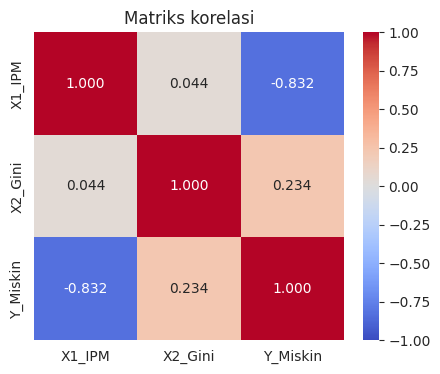

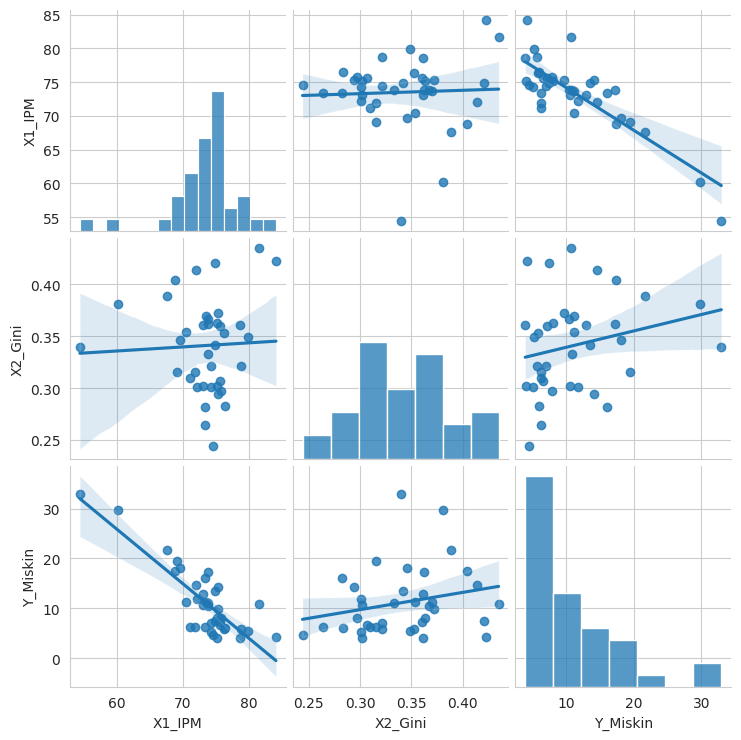

In [ ]:
corr = df[vars_].corr(method="pearson")
display(corr)

print("\nUji signifikansi korelasi Pearson:")
for i in range(len(vars_)):
    for j in range(i + 1, len(vars_)):
        r, p = stats.pearsonr(df[vars_[i]], df[vars_[j]])
        print(f"{vars_[i]} vs {vars_[j]}: r = {r:.4f}, p = {p:.4f}")

plt.figure(figsize=(5, 4))
sns.heatmap(corr, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriks korelasi"); plt.show()

sns.pairplot(df[vars_], kind="reg", diag_kind="hist")
plt.show()

**Bentuk model regresi**

In [ ]:
X = sm.add_constant(df[["X1_IPM", "X2_Gini"]])
y = df["Y_Miskin"]
model = sm.OLS(y, X).fit()
print(model.summary())

resid = model.resid
fitted = model.fittedvalues

                            OLS Regression Results                            
Dep. Variable:               Y_Miskin   R-squared:                       0.765
Model:                            OLS   Adj. R-squared:                  0.752
Method:                 Least Squares   F-statistic:                     57.11
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           9.54e-12
Time:                        06:34:18   Log-Likelihood:                -98.405
No. Observations:                  38   AIC:                             202.8
Df Residuals:                      35   BIC:                             207.7
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         78.9736      8.785      8.990      0.0

**Uji normalitas residual**

,Statistik,p-value,Kesimpulan
Shapiro-Wilk,0.9746,0.5280,Normal
Jarque-Bera,0.7940,0.6723,Normal
Kolmogorov-Smirnov (Lilliefors),0.0815,0.7556,Normal


H0: residual berdistribusi normal | tolak H0 jika p-value < 0.05


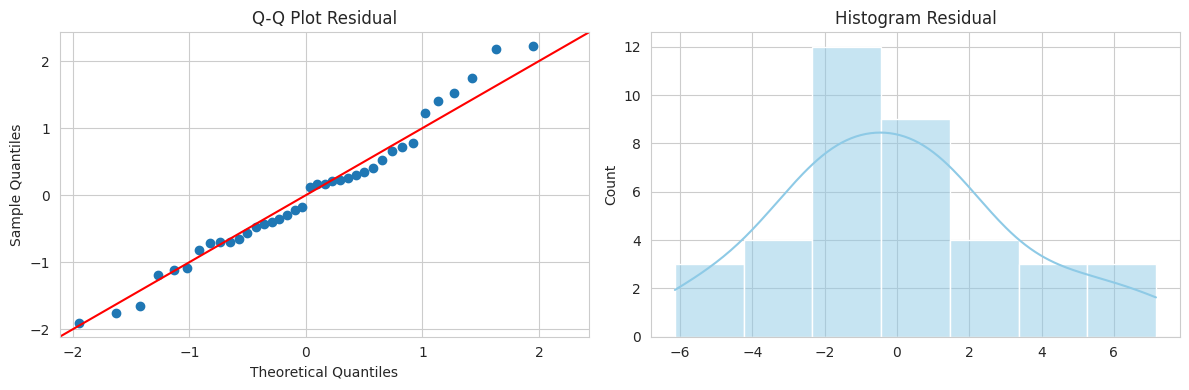

In [ ]:
sw_stat, sw_p = stats.shapiro(resid)
jb_stat, jb_p, jb_skew, jb_kurt = jarque_bera(resid)
ks_stat, ks_p = lilliefors(resid, dist="norm")

norm = pd.DataFrame({
    "Statistik": [sw_stat, jb_stat, ks_stat],
    "p-value": [sw_p, jb_p, ks_p],
    "Kesimpulan": ["Normal" if p > ALPHA else "Tidak normal" for p in [sw_p, jb_p, ks_p]]
}, index=["Shapiro-Wilk", "Jarque-Bera", "Kolmogorov-Smirnov (Lilliefors)"])
display(norm)
print(f"H0: residual berdistribusi normal | tolak H0 jika p-value < {ALPHA}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sm.qqplot(resid, line="45", fit=True, ax=ax[0]); ax[0].set_title("Q-Q Plot Residual")
sns.histplot(resid, kde=True, ax=ax[1], color="#8ecae6"); ax[1].set_title("Histogram Residual")
plt.tight_layout(); plt.show()

**Uji multikolinearitas**

In [ ]:
vif = pd.DataFrame({
    "Variabel": ["X1_IPM", "X2_Gini"],
    "VIF": [variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
})
vif["Tolerance"] = 1 / vif["VIF"]
vif["Kesimpulan"] = np.where(vif["VIF"] < 10, "Tidak ada multikolinearitas", "Ada multikolinearitas")
display(vif.set_index("Variabel"))

r12 = df["X1_IPM"].corr(df["X2_Gini"])
print(f"Korelasi X1 dan X2 = {r12:.4f}")
print("Kriteria umum: VIF < 10 dan Tolerance > 0.10 -> tidak ada multikolinearitas.")

,VIF,Tolerance,Kesimpulan
Variabel,,,
X1_IPM,1.0020,0.9981,Tidak ada multikolinearitas
X2_Gini,1.0020,0.9981,Tidak ada multikolinearitas


Korelasi X1 dan X2 = 0.0441
Kriteria umum: VIF < 10 dan Tolerance > 0.10 -> tidak ada multikolinearitas.


**Uji heteroskedastisitas**

,Statistik,p-value,Kesimpulan
Breusch-Pagan (LM),0.5976,0.7417,Homoskedastis
White (LM),5.5992,0.3472,Homoskedastis
Glejser (F),0.0745,0.9283,Homoskedastis


H0: homoskedastisitas | tolak H0 jika p-value < 0.05

Glejser - p-value per variabel:


,p-value
X1_IPM,0.8144
X2_Gini,0.7545


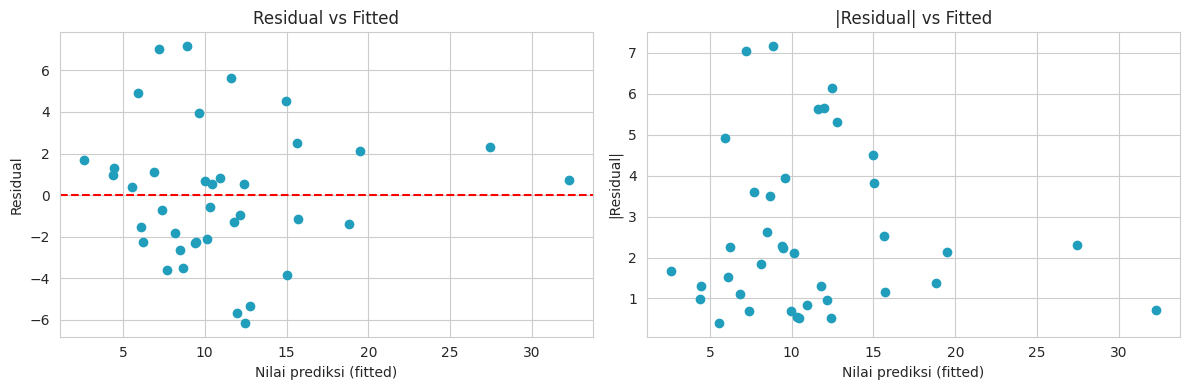

In [ ]:
bp_lm, bp_p, bp_f, bp_fp = het_breuschpagan(resid, X)
wh_lm, wh_p, wh_f, wh_fp = het_white(resid, X)

# Glejser: regresi |residual| terhadap variabel X
glej = sm.OLS(resid.abs(), X).fit()

het = pd.DataFrame({
    "Statistik": [bp_lm, wh_lm, glej.fvalue],
    "p-value": [bp_p, wh_p, glej.f_pvalue],
    "Kesimpulan": ["Homoskedastis" if p > ALPHA else "Heteroskedastis"
                   for p in [bp_p, wh_p, glej.f_pvalue]]
}, index=["Breusch-Pagan (LM)", "White (LM)", "Glejser (F)"])
display(het)
print(f"H0: homoskedastisitas | tolak H0 jika p-value < {ALPHA}")

print("\nGlejser - p-value per variabel:")
display(glej.pvalues.drop("const").to_frame("p-value"))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(fitted, resid, color="#219ebc")
ax[0].axhline(0, color="red", ls="--")
ax[0].set_xlabel("Nilai prediksi (fitted)"); ax[0].set_ylabel("Residual")
ax[0].set_title("Residual vs Fitted")
ax[1].scatter(fitted, resid.abs(), color="#219ebc")
ax[1].set_xlabel("Nilai prediksi (fitted)"); ax[1].set_ylabel("|Residual|")
ax[1].set_title("|Residual| vs Fitted")
plt.tight_layout(); plt.show()

**Uji t Parsial**

In [ ]:
t_tab = stats.t.ppf(1 - ALPHA / 2, dfres)
ci = model.conf_int()
koef = pd.DataFrame({
    "Koefisien (B)": model.params,
    "Std. Error": model.bse,
    "t hitung": model.tvalues,
    "p-value": model.pvalues,
    "CI 95% bawah": ci[0],
    "CI 95% atas": ci[1],
})
koef["t tabel"] = t_tab
koef["Keputusan"] = np.where(koef["p-value"] < ALPHA, "Signifikan", "Tidak signifikan")
koef.index = ["Konstanta", "IPM (X1)", "Gini (X2)"]
display(koef)
print(f"t tabel (alpha={ALPHA}, df={dfres}) = {t_tab:.4f}")

,Koefisien (B),Std. Error,t hitung,p-value,CI 95% bawah,CI 95% atas,t tabel,Keputusan
Konstanta,78.9736,8.7846,8.9899,0.0000,61.1398,96.8073,2.0301,Signifikan
IPM (X1),-1.1090,0.1077,-10.2977,0.0000,-1.3277,-0.8904,2.0301,Signifikan
Gini (X2),40.1306,12.1241,3.3100,0.0022,15.5173,64.7438,2.0301,Signifikan


t tabel (alpha=0.05, df=35) = 2.0301


**Uji F (simultan/kelayakan model)**

In [ ]:
F_tab = stats.f.ppf(1 - ALPHA, k, dfres)
uji_f = pd.DataFrame({
    "F hitung": [model.fvalue], "F tabel": [F_tab],
    "df (k, n-k-1)": [f"({k}, {dfres})"], "p-value": [model.f_pvalue],
    "Keputusan": ["Model layak (tolak H0)" if model.f_pvalue < ALPHA else "Model tidak layak"]
}, index=["Uji F"])
display(uji_f)

,F hitung,F tabel,"df (k, n-k-1)",p-value,Keputusan
Uji F,57.1068,3.2674,"(2, 35)",0.0000,Model layak (tolak H0)


**Koefisien Determinasi**

In [ ]:
t2 = model.tvalues[["X1_IPM", "X2_Gini"]] ** 2
r2_parsial = t2 / (t2 + dfres)      # kontribusi unik tiap variabel

det = pd.DataFrame({
    "Nilai": [model.rsquared, model.rsquared_adj, np.sqrt(model.mse_resid),
              r2_parsial["X1_IPM"], r2_parsial["X2_Gini"]]
}, index=["R-squared", "Adjusted R-squared", "Std. error regresi (SEE)",
          "R2 parsial IPM", "R2 parsial Gini"])
display(det)
print(f"Adjusted R2 = {model.rsquared_adj:.4f} -> {model.rsquared_adj*100:.1f}% variasi persentase "
      f"penduduk miskin dijelaskan IPM dan Gini; sisanya {100-model.rsquared_adj*100:.1f}% faktor lain.")

,Nilai
R-squared,0.7654
Adjusted R-squared,0.7520
Std. error regresi (SEE),3.3595
R2 parsial IPM,0.7518
R2 parsial Gini,0.2384


Adjusted R2 = 0.7520 -> 75.2% variasi persentase penduduk miskin dijelaskan IPM dan Gini; sisanya 24.8% faktor lain.


**Koefisien Terstandar (Beta)**

In [ ]:
sd = df[["X1_IPM", "X2_Gini", "Y_Miskin"]].std()
beta = pd.Series({
    "IPM (X1)": model.params["X1_IPM"] * sd["X1_IPM"] / sd["Y_Miskin"],
    "Gini (X2)": model.params["X2_Gini"] * sd["X2_Gini"] / sd["Y_Miskin"],
}, name="Beta terstandar")
display(beta.to_frame())
print("Variabel dengan pengaruh relatif terbesar:", beta.abs().idxmax())

,Beta terstandar
IPM (X1),-0.8438
Gini (X2),0.2712


Variabel dengan pengaruh relatif terbesar: IPM (X1)


**Uji Ketahanan Hasil (Robust SE HC3)**

In [ ]:
# Robust SE HC3
rob = model.get_robustcov_results(cov_type="HC3")
cek_rob = pd.DataFrame({
    "SE biasa": model.bse.values, "SE robust (HC3)": rob.bse,
    "p biasa": model.pvalues.values, "p robust (HC3)": rob.pvalues,
}, index=["Konstanta", "IPM (X1)", "Gini (X2)"])
display(cek_rob)

,SE biasa,SE robust (HC3),p biasa,p robust (HC3)
Konstanta,8.7846,8.7679,0.0000,0.0000
IPM (X1),0.1077,0.0849,0.0000,0.0000
Gini (X2),12.1241,14.0301,0.0022,0.0071


**Uji Ketahanan Hasil (Cook's distance dan leverage)**

In [ ]:
# Cook's distance dan leverage
infl = model.get_influence()
pengaruh = df[["Provinsi"]].copy()
pengaruh["Cook's D"] = infl.cooks_distance[0]
pengaruh["Leverage"] = infl.hat_matrix_diag
pengaruh["Std. residual"] = infl.resid_studentized_internal
display(pengaruh.sort_values("Cook's D", ascending=False).head(5))
print(f"Ambang Cook's D = 4/n = {4/n:.3f}; leverage tinggi jika > 2(k+1)/n = {2*(k+1)/n:.3f}")

,Provinsi,Cook's D,Leverage,Std. residual
13,DI Yogyakarta,0.2253,0.2012,1.6384
30,Maluku,0.1261,0.0717,2.2131
11,Jawa Barat,0.1166,0.1104,-1.6787
0,Aceh,0.0986,0.0596,2.1596
36,Papua Tengah,0.0627,0.2329,0.7873


Ambang Cook's D = 4/n = 0.105; leverage tinggi jika > 2(k+1)/n = 0.158


**Uji Ketahanan Hasil (Sensitivitas: regresi ulang tanpa outlier)**

In [ ]:
# Sensitivitas: regresi ulang tanpa provinsi Papua yang menjadi outlier
def ringkas(data, label):
    Xs = sm.add_constant(data[["X1_IPM", "X2_Gini"]])
    m = sm.OLS(data["Y_Miskin"], Xs).fit()
    return pd.Series({
        "n": int(m.nobs),
        "B IPM": m.params["X1_IPM"], "p IPM": m.pvalues["X1_IPM"],
        "B Gini": m.params["X2_Gini"], "p Gini": m.pvalues["X2_Gini"],
        "Adj R2": m.rsquared_adj, "p (F)": m.f_pvalue}, name=label)

papua = ["Papua Pegunungan", "Papua Tengah"]
sens = pd.DataFrame([
    ringkas(df, "Semua provinsi"),
    ringkas(df[df.Provinsi != "Papua Pegunungan"], "Tanpa Papua Pegunungan"),
    ringkas(df[~df.Provinsi.isin(papua)], "Tanpa 2 provinsi Papua"),
])
display(sens)

,n,B IPM,p IPM,B Gini,p Gini,Adj R2,p (F)
Semua provinsi,38.0000,-1.1090,0.0000,40.1306,0.0022,0.7520,0.0000
Tanpa Papua Pegunungan,37.0000,-1.0856,0.0000,40.0310,0.0026,0.6507,0.0000
Tanpa 2 provinsi Papua,36.0000,-0.9869,0.0000,37.3686,0.0055,0.5023,0.0000


**Keputusan Hipotesis**

In [ ]:
b1, b2 = model.params["X1_IPM"], model.params["X2_Gini"]
p1, p2 = model.pvalues["X1_IPM"], model.pvalues["X2_Gini"]
# H1 dan H2 searah (satu arah): p satu sisi = p/2 jika tanda sesuai
h1 = (b1 < 0) and (p1 / 2 < ALPHA)
h2 = (b2 > 0) and (p2 / 2 < ALPHA)
h3 = model.f_pvalue < ALPHA
hasil = pd.DataFrame({
    "Hipotesis": ["H1: IPM berpengaruh negatif terhadap Y",
                  "H2: Gini berpengaruh positif terhadap Y",
                  "H3: IPM dan Gini berpengaruh simultan terhadap Y"],
    "Bukti": [f"B={b1:.4f}, p={p1:.4f}", f"B={b2:.4f}, p={p2:.4f}", f"F={model.fvalue:.2f}, p={model.f_pvalue:.2e}"],
    "Keputusan": ["Diterima" if h else "Ditolak" for h in (h1, h2, h3)],
})
display(hasil)

,Hipotesis,Bukti,Keputusan
0,H1: IPM berpengaruh negatif terhadap Y,"B=-1.1090, p=0.0000",Diterima
1,H2: Gini berpengaruh positif terhadap Y,"B=40.1306, p=0.0022",Diterima
2,H3: IPM dan Gini berpengaruh simultan terhadap Y,"F=57.11, p=9.54e-12",Diterima


**Visualisasi**

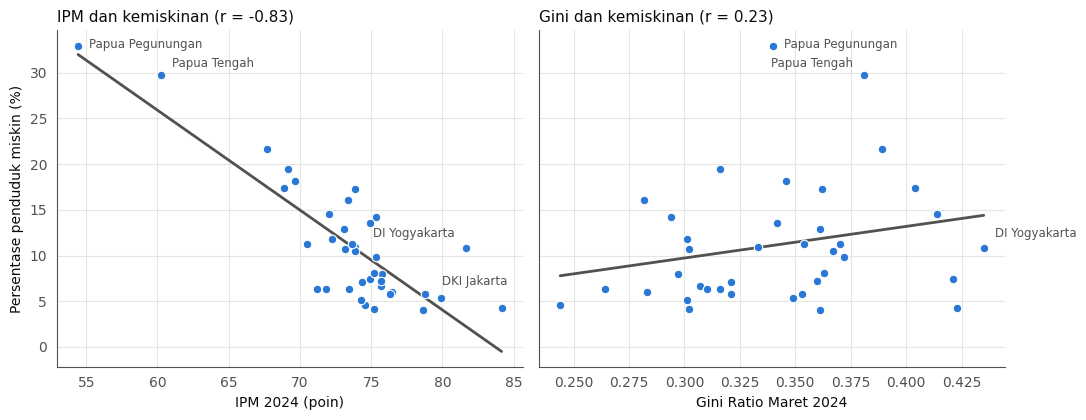

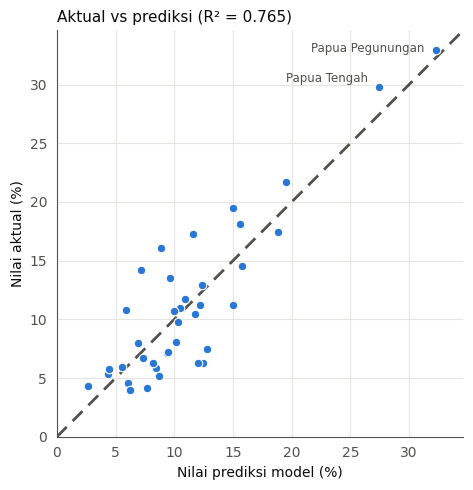

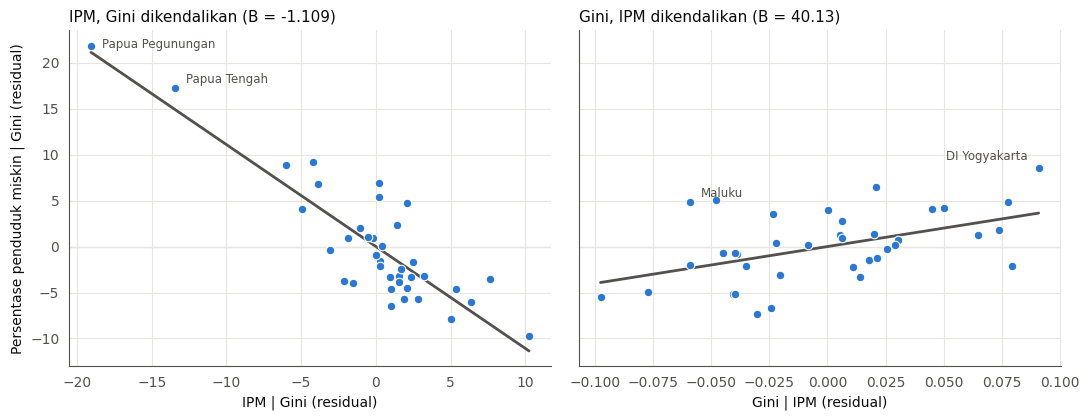

In [ ]:
BIRU, INK, INK2, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": INK2, "axes.labelcolor": INK,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.8, "axes.axisbelow": True})
SOROT = {"Papua Pegunungan": (8, -2), "Papua Tengah": (8, 6), "DKI Jakarta": (4, 16, "right"),
         "DI Yogyakarta": (-8, 8)}           # {provinsi: (geser x, geser y[, rata teks])} dalam poin

def beri_label(ax, xs, ys, nama, geser=SOROT):
    for i, p in enumerate(nama):
        if p in geser:
            g = geser[p]; dx, dy = g[0], g[1]
            ha = g[2] if len(g) > 2 else ("left" if dx > 0 else "right")
            ax.annotate(p, (xs[i], ys[i]), xytext=(dx, dy), textcoords="offset points",
                        ha=ha, fontsize=8.5, color=INK2)

def titik(ax, x, y):
    ax.scatter(x, y, s=38, color=BIRU, edgecolor="white", linewidth=0.8, zorder=3)

def garis_tren(ax, x, y):
    b1, b0 = np.polyfit(x, y, 1)
    xs = np.linspace(np.min(x), np.max(x), 100)
    ax.plot(xs, b0 + b1 * xs, color=INK2, lw=2, zorder=2)
    return b1

nama = df["Provinsi"].values
xi, xg, yy = df["X1_IPM"].values, df["X2_Gini"].values, df["Y_Miskin"].values
params = model.params.values
fitted = np.c_[np.ones(len(df)), xi, xg] @ params

# Gambar 1: diagram pencar variabel bebas terhadap Y (hubungan bivariat)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
titik(ax[0], xi, yy); r1 = np.corrcoef(xi, yy)[0, 1]; garis_tren(ax[0], xi, yy)
beri_label(ax[0], xi, yy, nama)
ax[0].set_xlabel("IPM 2024 (poin)"); ax[0].set_ylabel("Persentase penduduk miskin (%)")
ax[0].set_title(f"IPM dan kemiskinan (r = {r1:.2f})", loc="left", fontsize=11, color=INK)
titik(ax[1], xg, yy); r2 = np.corrcoef(xg, yy)[0, 1]; garis_tren(ax[1], xg, yy)
beri_label(ax[1], xg, yy, nama, {"Papua Pegunungan": (8, -2), "Papua Tengah": (-8, 6),
                                  "DI Yogyakarta": (8, 8)})
ax[1].set_xlabel("Gini Ratio Maret 2024")
ax[1].set_title(f"Gini dan kemiskinan (r = {r2:.2f})", loc="left", fontsize=11, color=INK)
plt.tight_layout(); plt.savefig("gambar1_scatter.png", dpi=200); plt.show()

# Gambar 2: nilai aktual vs prediksi model
fig, ax = plt.subplots(figsize=(5.4, 5))
lo, hi = 0, max(yy.max(), fitted.max()) * 1.05
ax.plot([lo, hi], [lo, hi], color=INK2, lw=2, ls=(0, (5, 3)), zorder=2)
titik(ax, fitted, yy); beri_label(ax, fitted, yy, nama, {"Papua Pegunungan": (-8, -2), "Papua Tengah": (-8, 4)})
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
ax.set_xlabel("Nilai prediksi model (%)"); ax.set_ylabel("Nilai aktual (%)")
ax.set_title(f"Aktual vs prediksi (R² = {model.rsquared:.3f})", loc="left", fontsize=11, color=INK)
plt.tight_layout(); plt.savefig("gambar2_aktual_prediksi.png", dpi=200); plt.show()

# Gambar 3: partial regression (added-variable) plot, hubungan tiap X setelah variabel lain dikendalikan
def resid_atas(a, z):
    Z = np.c_[np.ones(len(z)), z]
    return a - Z @ np.linalg.lstsq(Z, a, rcond=None)[0]

fig, ax = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
ex, ey = resid_atas(xi, xg), resid_atas(yy, xg)
titik(ax[0], ex, ey); s1 = garis_tren(ax[0], ex, ey)
beri_label(ax[0], ex, ey, nama, {"Papua Pegunungan": (8, -2), "Papua Tengah": (8, 4)})
ax[0].set_xlabel("IPM | Gini (residual)"); ax[0].set_ylabel("Persentase penduduk miskin | Gini (residual)")
ax[0].set_title(f"IPM, Gini dikendalikan (B = {s1:.3f})", loc="left", fontsize=11, color=INK)
ex, ey = resid_atas(xg, xi), resid_atas(yy, xi)
titik(ax[1], ex, ey); s2 = garis_tren(ax[1], ex, ey)
beri_label(ax[1], ex, ey, nama, {"DI Yogyakarta": (-8, 6), "Maluku": (8, 4)})
ax[1].set_xlabel("Gini | IPM (residual)")
ax[1].set_title(f"Gini, IPM dikendalikan (B = {s2:.2f})", loc="left", fontsize=11, color=INK)
for a in ax: a.axhline(0, color=GRID, lw=1, zorder=1)
plt.tight_layout(); plt.savefig("gambar3_partial_regression.png", dpi=200); plt.show()